In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns


In [2]:
data = pd.read_csv('/home/entr0py/Python/ai-ml-log/ML_ZoomCamp/car_price_predictor(session 2)/data.csv')


In [3]:
data.columns = data.columns.str.strip().str.lower().str.replace(' ', '_').str.replace('(', '').str.replace(')', '')
data.columns

Index(['make', 'model', 'year', 'engine_fuel_type', 'engine_hp',
       'engine_cylinders', 'transmission_type', 'driven_wheels',
       'number_of_doors', 'market_category', 'vehicle_size', 'vehicle_style',
       'highway_mpg', 'city_mpg', 'popularity', 'msrp'],
      dtype='str')

In [4]:
string = data.dtypes[data.dtypes =='string'].index
string

for col in string:
    data[col] = data[col].str.strip().str.lower().str.replace(' ', '_').str.replace('(', '').str.replace(')', '')


In [5]:
data.head()

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,bmw,1_series_m,2011,premium_unleaded_required,335.0,6.0,manual,rear_wheel_drive,2.0,"factory_tuner,luxury,high-performance",compact,coupe,26,19,3916,46135
1,bmw,1_series,2011,premium_unleaded_required,300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,convertible,28,19,3916,40650
2,bmw,1_series,2011,premium_unleaded_required,300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,high-performance",compact,coupe,28,20,3916,36350
3,bmw,1_series,2011,premium_unleaded_required,230.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,coupe,28,18,3916,29450
4,bmw,1_series,2011,premium_unleaded_required,230.0,6.0,manual,rear_wheel_drive,2.0,luxury,compact,convertible,28,18,3916,34500


In [6]:
for col in data.columns:
    print(col)
    print(data[col].unique()[:5])
    print(data[col].nunique())
    print()

make
<StringArray>
['bmw', 'audi', 'fiat', 'mercedes-benz', 'chrysler']
Length: 5, dtype: str
48

model
<StringArray>
['1_series_m', '1_series', '100', '124_spider', '190-class']
Length: 5, dtype: str
914

year
[2011 2012 2013 1992 1993]
28

engine_fuel_type
<StringArray>
[   'premium_unleaded_required',             'regular_unleaded',
 'premium_unleaded_recommended',       'flex-fuel_unleaded/e85',
                       'diesel']
Length: 5, dtype: str
10

engine_hp
[335. 300. 230. 320. 172.]
356

engine_cylinders
[ 6.  4.  5.  8. 12.]
9

transmission_type
<StringArray>
['manual', 'automatic', 'automated_manual', 'direct_drive', 'unknown']
Length: 5, dtype: str
5

driven_wheels
<StringArray>
['rear_wheel_drive', 'front_wheel_drive', 'all_wheel_drive',
 'four_wheel_drive']
Length: 4, dtype: str
4

number_of_doors
[ 2.  4.  3. nan]
3

market_category
<StringArray>
['factory_tuner,luxury,high-performance',
                    'luxury,performance',
               'luxury,high-performance'

In [7]:
import matplotlib.pyplot as plt
import seaborn as sbs

%matplotlib inline

<Axes: xlabel='msrp', ylabel='Count'>

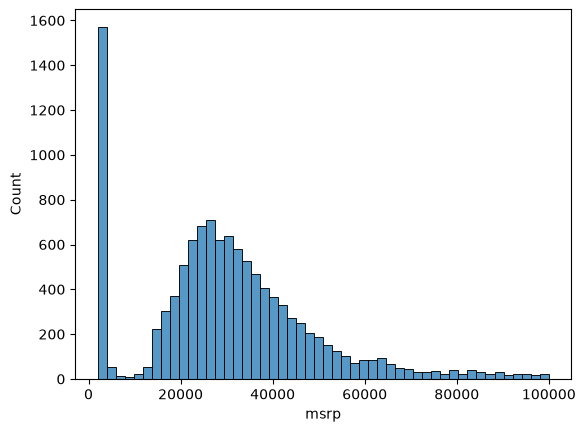

In [8]:
sbs.histplot(data.msrp[data.msrp < 100000], bins = 50)

<Axes: xlabel='msrp', ylabel='Count'>

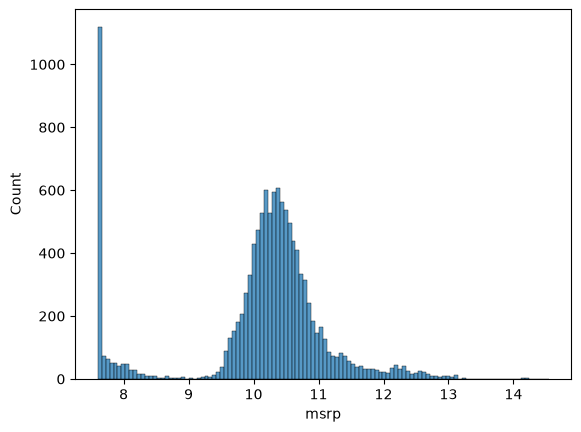

In [9]:
price_log = np.log1p(data.msrp)
sbs.histplot(price_log)

In [10]:
n = int(len(data))
n_val = int(len(data) * 0.2)
n_test = int(len(data) * 0.2)
n_train= n - (n_val + n_test)

print(n_val +n_test+n_train , n)

11914 11914


In [11]:
df_Val = data.iloc[:n_val]
df_test = data.iloc[n_val:n_val+ n_test]
df_train = data.iloc[n_val + n_test:]

In [12]:
np.random.seed(2)
idx = np.arange(n)
np.random.shuffle(idx)

In [13]:
df_train = data.iloc[idx[:n_train]]
df_val = data.iloc[idx[n_train:n_train+n_val]]
df_test = data.iloc[idx[n_train+n_val:]]


In [14]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [15]:
print(len(df_train), len(df_test) ,len(df_val) )

7150 2382 2382


In [16]:
y_train = np.log1p(df_train.msrp.values)
y_test = np.log1p(df_test.msrp.values)
y_val = np.log1p(df_val.msrp.values)

In [17]:
del df_train['msrp']
del df_test['msrp']
del df_val['msrp']

# Linear_Regression


In [18]:
df_train.iloc[10]

make                               rolls-royce
model                   phantom_drophead_coupe
year                                      2015
engine_fuel_type     premium_unleaded_required
engine_hp                                453.0
engine_cylinders                          12.0
transmission_type                    automatic
driven_wheels                 rear_wheel_drive
number_of_doors                            2.0
market_category      exotic,luxury,performance
vehicle_size                             large
vehicle_style                      convertible
highway_mpg                                 19
city_mpg                                    11
popularity                                  86
Name: 10, dtype: object

In [19]:
xi = [453 , 11 , 86]
demo_w0 = 7.12
demo_w = [0.01 , 0.02 , 0.004]
def linear_regression(xi):
    l = len(xi)
    pred = demo_w0

    for j in range(l):
        pred = pred+ demo_w[j]*xi[j]
    return pred

print(linear_regression(xi))
        

12.214


In [20]:
demo_w_full = [demo_w0] + demo_w
demo_xi_full = [1] + xi
np.dot(demo_xi_full, demo_w_full)

np.float64(12.214)

In [21]:
xi = np.array([453 , 11 , 86])
demo_w0 = 7.12
demo_w = np.array([0.01 , 0.02 , 0.004])

pred = demo_w0 + np.dot(xi , demo_w)
print(pred)

12.214


In [22]:
x1 = [12,34,305]
x2 = [11,64,260]
x3 = [19,24,410]

X = np.array([x1,x2,x3])
X_full = np.column_stack([np.ones(X.shape[0]), X])

X_full.dot(demo_w_full)


array([9.14, 9.55, 9.43])

In [23]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)

    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

In [24]:
df_train.dtypes

make                     str
model                    str
year                   int64
engine_fuel_type         str
engine_hp            float64
engine_cylinders     float64
transmission_type        str
driven_wheels            str
number_of_doors      float64
market_category          str
vehicle_size             str
vehicle_style            str
highway_mpg            int64
city_mpg               int64
popularity             int64
dtype: object

In [25]:
df_train.columns

Index(['make', 'model', 'year', 'engine_fuel_type', 'engine_hp',
       'engine_cylinders', 'transmission_type', 'driven_wheels',
       'number_of_doors', 'market_category', 'vehicle_size', 'vehicle_style',
       'highway_mpg', 'city_mpg', 'popularity'],
      dtype='str')

In [26]:
base = ['engine_hp', 'engine_cylinders', 'highway_mpg', 'city_mpg', 'popularity']
df_train[base]

,engine_hp,engine_cylinders,highway_mpg,city_mpg,popularity
0,148.0,4.0,33,24,1385
1,132.0,4.0,32,25,2031
2,148.0,4.0,37,28,640
3,90.0,4.0,18,16,873
4,385.0,8.0,21,15,5657
...,...,...,...,...,...
7145,300.0,6.0,31,20,3916
7146,210.0,4.0,30,24,873
7147,285.0,6.0,22,17,549
7148,563.0,12.0,21,13,86


In [27]:
# X_train = df_train[base].isnull().sum()
# X_train

In [28]:
X_train = df_train[base].fillna(0).values

In [29]:
w0 , w = train_linear_regression(X_train , y_train)

In [30]:
# Re-train immediately so stale demo weights can never be used here.
w0, w = train_linear_regression(X_train, y_train)
assert w.shape[0] == X_train.shape[1]
y_train_pred = w0 + X_train.dot(w)
y_train_pred

array([ 9.54792783,  9.38733977,  9.67197758, ..., 10.30423015,
       11.9778914 ,  9.99863111], shape=(7150,))

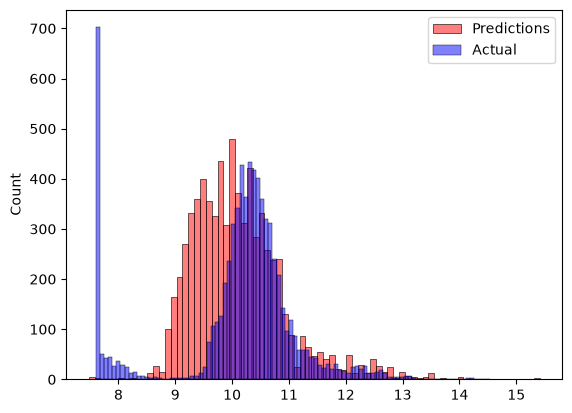

In [31]:
sns.histplot(y_train_pred, color='red', alpha=0.5, label='Predictions')
sns.histplot(y_train, color='blue', alpha=0.5, label='Actual')
plt.legend()
plt.show()

In [32]:
def rmse(y , y_pred):
    se = ((y - y_pred)**2)
    mse = se.mean()
    return np.sqrt(mse)



In [33]:
rmse(y_train, y_train_pred)

np.float64(0.7554192603920132)

# Validating the dataset


In [34]:
def prepare_X(df):
    df_num = df[base]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

In [35]:
X_train = prepare_X(df_train)
w0 , w = train_linear_regression(X_train , y_train)


X_val = prepare_X(df_val)
y_val_pred = w0 + X_val.dot(w)

In [36]:
rmse(y_val, y_val_pred)

np.float64(0.761653099130156)

# Adding new feature

In [37]:
def prepare_X(df):
    df_num = df.copy()
    df_num['age'] = 2017 - df_num['year']
    features = base + ['age']

    df_num = df_num[features]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

In [38]:
X_train = prepare_X(df_train)
w0 , w = train_linear_regression(X_train , y_train)


X_val = prepare_X(df_val)
y_val_pred = w0 + X_val.dot(w)

rmse(y_val, y_val_pred)

np.float64(0.5172055461058299)

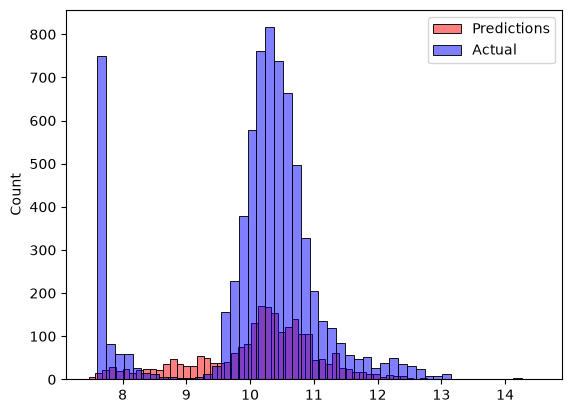

In [39]:
sns.histplot(y_val_pred, color='red', alpha=0.5, label='Predictions', bins = 50)
sns.histplot(y_train, color='blue', alpha=0.5, label='Actual'   , bins = 50)
plt.legend()
plt.show()

In [40]:
for v in [2 , 3 , 4]:    
    df_train['num_doors_%s' %v ] = (df_train.number_of_doors == v).astype('int')

In [41]:
# del df_train['num_doors_%s']
df_train

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,num_doors_2,num_doors_3,num_doors_4
0,chevrolet,cobalt,2008,regular_unleaded,148.0,4.0,manual,front_wheel_drive,2.0,NaN,compact,coupe,33,24,1385,1,0,0
1,toyota,matrix,2012,regular_unleaded,132.0,4.0,automatic,front_wheel_drive,4.0,hatchback,compact,4dr_hatchback,32,25,2031,0,0,1
2,subaru,impreza,2016,regular_unleaded,148.0,4.0,automatic,all_wheel_drive,4.0,hatchback,compact,4dr_hatchback,37,28,640,0,0,1
3,volkswagen,vanagon,1991,regular_unleaded,90.0,4.0,manual,rear_wheel_drive,3.0,NaN,large,passenger_minivan,18,16,873,0,1,0
4,ford,f-150,2017,flex-fuel_unleaded/e85,385.0,8.0,automatic,four_wheel_drive,4.0,flex_fuel,large,crew_cab_pickup,21,15,5657,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7145,bmw,4_series,2015,premium_unleaded_required,300.0,6.0,automatic,rear_wheel_drive,2.0,"luxury,performance",midsize,convertible,31,20,3916,1,0,0
7146,volkswagen,beetle,2015,premium_unleaded_recommended,210.0,4.0,automated_manual,front_wheel_drive,2.0,"hatchback,performance",compact,2dr_hatchback,30,24,873,1,0,0
7147,gmc,sierra_1500,2015,flex-fuel_unleaded/e85,285.0,6.0,automatic,four_wheel_drive,4.0,flex_fuel,large,extended_cab_pickup,22,17,549,0,0,1
7148,rolls-royce,ghost,2014,premium_unleaded_required,563.0,12.0,automatic,rear_wheel_drive,4.0,"exotic,luxury,performance",large,sedan,21,13,86,0,0,1


In [55]:
makes = list(data.make.value_counts().head().index)

In [56]:
def prepare_X(df):
    df = df.copy()
    features = base.copy()

    df['age'] = 2017 - df['year']
    features.append('age')

    for v in [2, 3, 4]:
        column = 'num_doors_%s' % v
        df[column] = (df['number_of_doors'] == v).astype('int')
        features.append(column)

    for v in makes:
        column = 'make_%s' % v
        df[column] = (df.make == v).astype('int')
        features.append(column)

    df_num = df[features].fillna(0)
    X = df_num.values
    return X

In [57]:
prepare_X(df_train)


array([[148.,   4.,  33., ...,   0.,   0.,   0.],
       [132.,   4.,  32., ...,   0.,   1.,   0.],
       [148.,   4.,  37., ...,   0.,   0.,   0.],
       ...,
       [285.,   6.,  22., ...,   0.,   0.,   0.],
       [563.,  12.,  21., ...,   0.,   0.,   0.],
       [200.,   4.,  31., ...,   1.,   0.,   0.]], shape=(7150, 14))

np.float64(0.5076038849556795)

In [63]:
def train_linear_regression_reg(X, y, r=0.001):

    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTy = X.T.dot(y)

    R = np.eye(XTX.shape[0])
    R[0, 0] = 0

    w_full = np.linalg.solve(
        XTX + r * R,
        XTy
    )

    return w_full[0], w_full[1:]

In [ ]:
for r in [0, 0.001, 0.1, 1, 10, 100]:

    w0, w = train_linear_regression_reg(
        X_train, y_train, r
    )

    print(
        f"r={r:<7}",
        f"norm={np.linalg.norm(w):.6f}",
        f"train={rmse(y_train, w0 + X_train.dot(w)):.5f}",
        f"val={rmse(y_val, w0 + X_val.dot(w)):.5f}"
    )

r=0       norm=2.369024 train=0.50589 val=0.50760
r=0.001   norm=2.367820 train=0.50589 val=0.50760
r=0.1     norm=2.254784 train=0.50589 val=0.50761
r=1       norm=1.591355 train=0.50606 val=0.50768
r=10      norm=0.604392 train=0.50689 val=0.50779
r=100     norm=0.378923 train=0.50783 val=0.50814
